In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Library Google Colab untuk Mount Drive
from google.colab import drive

# Library Preprocessing & Model Evaluation
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_PATH = '/content/drive/MyDrive/smt 7/swarm/train.csv'

df_raw = pd.read_csv(DATA_PATH)

In [ ]:
print(f"Data Berhasil Dimuat! Ukuran Dataset: {df_raw.shape}")
df_raw.head()

Data Berhasil Dimuat! Ukuran Dataset: (8693, 14)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [ ]:
def engineer_features(df):
  df_feat = df.copy()
  # Ukuruan kelompok dari passenger id
  df_feat['Group'] = df_feat['PassengerId'].apply(lambda x: x.split('_')[0])
  group_sizes = df_feat['Group'].value_counts()
  df_feat['GroupSize'] = df_feat['Group'].map(group_sizes)

  # B. Parsing Kabin (Deck / Num / Side)
  cabin_split = df_feat['Cabin'].str.split('/', expand=True)
  df_feat['Deck'] = cabin_split[0]
  df_feat['Num'] = pd.to_numeric(cabin_split[1], errors='coerce')
  df_feat['Side'] = cabin_split[2]

    # C. Fitur Total Pengeluaran (Total Spending & IsZeroSpender)
  expenditures = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
  df_feat['TotalSpending'] = df_feat[expenditures].sum(axis=1)
  df_feat['IsZeroSpender'] = (df_feat['TotalSpending'] == 0).astype(int)

    # Drop kolom mentah yang sudah diekstrak / tidak relevan
  drop_cols = ['PassengerId', 'Name', 'Cabin', 'Group']
  df_feat = df_feat.drop(
      columns=[c for c in drop_cols if c in df_feat.columns]
    )

  return df_feat

In [ ]:
# Apply Feature Engineering
df_engineered = engineer_features(df_raw)

# Separasi Fitur (X) dan Target (y)
X_raw = df_engineered.drop(columns=['Transported'])
y = df_engineered['Transported'].astype(int).values

In [ ]:
num_cols = [
    'Age',
    'RoomService',
    'FoodCourt',
    'ShoppingMall',
    'Spa',
    'VRDeck',
    'TotalSpending',
    'GroupSize',
    'Num',
]
cat_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side']
passthrough_cols = ['IsZeroSpender']

In [ ]:
num_pipeline = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

In [ ]:
cat_pipeline = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    [
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols),
        ('passthrough', 'passthrough', passthrough_cols),
    ]
)

In [ ]:
X = preprocessor.fit_transform(X_raw)

print(f'Preprocessing Selesai!')
print(f'Dimensi Matriks Fitur (X) : {X.shape}')
print(f'Dimensi Target Array (y)   : {y.shape}')
print(f'Sisa Missing Values di X  : {np.isnan(X).sum()}')

Preprocessing Selesai!
Dimensi Matriks Fitur (X) : (8693, 30)
Dimensi Target Array (y)   : (8693,)
Sisa Missing Values di X  : 0


In [ ]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

print("=" * 60)
print(f" SKEMA EVALUASI: {N_SPLITS}-FOLD STRATIFIED CROSS-VALIDATION ")
print("=" * 60)
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    y_tr_fold, y_val_fold = y[train_idx], y[val_idx]
    print(
        f"Fold {fold} | Train: {len(train_idx)} data (Positif: {np.mean(y_tr_fold):.2%}) | "
        f"Val: {len(val_idx)} data (Positif: {np.mean(y_val_fold):.2%})"
    )

 SKEMA EVALUASI: 5-FOLD STRATIFIED CROSS-VALIDATION 
Fold 1 | Train: 6954 data (Positif: 50.36%) | Val: 1739 data (Positif: 50.37%)
Fold 2 | Train: 6954 data (Positif: 50.36%) | Val: 1739 data (Positif: 50.37%)
Fold 3 | Train: 6954 data (Positif: 50.36%) | Val: 1739 data (Positif: 50.37%)
Fold 4 | Train: 6955 data (Positif: 50.37%) | Val: 1738 data (Positif: 50.35%)
Fold 5 | Train: 6955 data (Positif: 50.37%) | Val: 1738 data (Positif: 50.35%)


In [ ]:
X_tr_opt, X_val_opt, y_tr_opt, y_val_opt = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [ ]:
LOWER_BOUND = np.array([0.1, 0.0001])
UPPER_BOUND = np.array([1000.0, 10.0])
DIMENSION = len(LOWER_BOUND)

In [ ]:
WSA_CONFIG = {
    'n_whales': 20,  # Jumlah populasi paus dalam kawanan
    'max_iter': 20,  # Jumlah iterasi pencarian
    'rho_0': 2.0,  # Intensitas suara / faktor skala pergerakan awal
    'eta': 0.1,  # Koefisien atenusi gelombang ultrasonik
    'lb': LOWER_BOUND,
    'ub': UPPER_BOUND,
}

In [ ]:
class WhaleSwarmOptimizer:

    def __init__(self, config):
        self.n_whales = config['n_whales']
        self.max_iter = config['max_iter']
        self.rho_0 = config['rho_0']
        self.eta = config['eta']
        self.lb = config['lb']
        self.ub = config['ub']
        self.dim = len(self.lb)

    def init_population(self):
        """Inisialisasi posisi awal populasi paus secara acak uniform pada
        rentang [LB, UB]."""
        population = np.random.uniform(
            low=self.lb, high=self.ub, size=(self.n_whales, self.dim)
        )
        return population

    def apply_boundary(self, position):
        """Boundary Checking (Clamping) agar nilai C dan gamma tidak melenceng
        keluar batas sah."""
        return np.clip(position, self.lb, self.ub)

    def compute_distance(self, pos1, pos2):
        """Menghitung jarak Euclidean antar dua paus."""
        return np.linalg.norm(pos1 - pos2)

In [ ]:
print('Engine Optimasi WSA Berhasil Dikonfigurasi!')
print(
    f'Batas Pencarian C     : [{LOWER_BOUND[0]} - {UPPER_BOUND[0]}]'
)
print(
    f'Batas Pencarian Gamma : [{LOWER_BOUND[1]} - {UPPER_BOUND[1]}]'
)

Engine Optimasi WSA Berhasil Dikonfigurasi!
Batas Pencarian C     : [0.1 - 1000.0]
Batas Pencarian Gamma : [0.0001 - 10.0]


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC

In [ ]:
# def evaluate_svm_fitness_fast(solution, X_tr, y_tr, X_val, y_val):
#     c_val = float(solution[0])
#     gamma_val = float(solution[1])

#     # Inisialisasi & Fit SVM
#     clf = SVC(
#         C=c_val, gamma=gamma_val, kernel='rbf', random_state=42, cache_size=1000
#     )
#     clf.fit(X_tr, y_tr)

#     # Prediksi pada Validation Set
#     preds = clf.predict(X_val)
#     score = f1_score(y_val, preds, average='macro')

#     fitness = 1.0 - score
#     return fitness, score

def evaluate_svm_fitness_log(solution_log, X_tr, y_tr, X_val, y_val):
    # Konversi koordinat paus (log-space) ke nilai asli C dan Gamma
    c_val = float(10 ** solution_log[0])
    gamma_val = float(10 ** solution_log[1])

    clf = SVC(
        C=c_val, gamma=gamma_val, kernel='rbf', random_state=42, cache_size=1000
    )
    clf.fit(X_tr, y_tr)

    preds = clf.predict(X_val)
    score = f1_score(y_val, preds, average='macro')

    return 1.0 - score, score

In [ ]:
class WhaleSwarmOptimizer:

    def __init__(
        self,
        n_whales=20,
        max_iter=20,
        lb=[0.1, 0.0001],
        ub=[1000.0, 10.0],
        rho_0=2.0,
        eta=0.1,
    ):
        self.n_whales = n_whales
        self.max_iter = max_iter
        self.lb = np.array(lb)
        self.ub = np.array(ub)
        self.dim = len(lb)
        self.rho_0 = rho_0
        self.eta = eta

    def apply_boundary(self, pos):
        """Boundary Checking (Clamping) agar nilai tetap sah."""
        return np.clip(pos, self.lb, self.ub)

    def optimize(self, fitness_func, X, y):
        print('=' * 75)
        print(' MEMULAI PROSES OPTIMASI HYPERPARAMETER SVM DENGAN WSA ')
        print('=' * 75)

        # A. Inisialisasi Populasi Paus
        pop = np.random.uniform(self.lb, self.ub, (self.n_whales, self.dim))
        fitness_vals = np.zeros(self.n_whales)
        scores = np.zeros(self.n_whales)

        # B. Evaluasi Populasi Awal
        print('[+] Melakukan Evaluasi Populasi Awal...')
        for i in range(self.n_whales):
            fit, sc = fitness_func(pop[i], X, y)
            fitness_vals[i] = fit
            scores[i] = sc

        # C. Temukan Paus Terbaik Awal
        best_idx = np.argmin(fitness_vals)
        best_solution = pop[best_idx].copy()
        best_fitness = fitness_vals[best_idx]
        best_score = scores[best_idx]

        print(
            f'[*] Inisialisasi Selesai | Best Fitness: {best_fitness:.4f} | F1-Score: {best_score:.4f}'
        )
        print(f'    Best C: {best_solution[0]:.4f} | Best Gamma: {best_solution[1]:.4f}\n')

        history = [best_fitness]
        pop_history = [pop.copy()]
        # D. Loop Iterasi Utama
        for it in range(self.max_iter):
            for i in range(self.n_whales):
                # Cari paus terdekat yang memiliki fitness lebih unggul (makanan lebih berlimpah)
                better_indices = np.where(fitness_vals < fitness_vals[i])[0]

                if len(better_indices) > 0:
                    distances = [
                        np.linalg.norm(pop[i] - pop[j]) for j in better_indices
                    ]
                    target_idx = better_indices[np.argmin(distances)]
                    dist = np.min(distances)

                    # Pergerakan menuju target dengan peluruhan ultrasonik
                    step = self.rho_0 * np.exp(-self.eta * dist) * (
                        pop[target_idx] - pop[i]
                    ) + np.random.uniform(-0.1, 0.1, self.dim)
                    candidate_pos = pop[i] + step
                else:
                    # Jika paus i sudah yang terbaik, lakukan pencarian acak lokal
                    candidate_pos = pop[i] + np.random.uniform(
                        -0.05, 0.05, self.dim
                    ) * (self.ub - self.lb)

                # Boundary Checking
                candidate_pos = self.apply_boundary(candidate_pos)

                # Evaluasi Kandidat Posisi Baru
                cand_fit, cand_sc = fitness_func(candidate_pos, X, y)

                # Greedy Selection
                if cand_fit < fitness_vals[i]:
                    pop[i] = candidate_pos
                    fitness_vals[i] = cand_fit
                    scores[i] = cand_sc

                    if cand_fit < best_fitness:
                        best_fitness = cand_fit
                        best_solution = candidate_pos.copy()
                        best_score = cand_sc

            history.append(best_fitness)
            print(
                f'Iterasi {it+1:02d}/{self.max_iter:02d} | Best Fitness: {best_fitness:.4f} | '
                f'F1-Score: {best_score:.4f} | C: {best_solution[0]:.2f}, Gamma: {best_solution[1]:.4f}'
            )
            pop_history.append(pop.copy())

        print('=' * 75)
        print(' OPTIMASI SELESAI ')
        print('=' * 75)
        return best_solution, best_fitness, best_score, history, pop_history

In [ ]:
# wsa_engine = WhaleSwarmOptimizer(
#     n_whales=15,
#     max_iter=15,
#     lb=[0.1, 0.0001],
#     ub=[500.0, 1.0],  # Gamma dibatasi max 1.0
# )

wsa_log_engine = WhaleSwarmOptimizer(
    n_whales=10,
    max_iter=10,
    lb=[-1.0, -4.0],  # 10^-1 = 0.1  dan 10^-4 = 0.0001
    ub=[3.0, 0.0],  # 10^3  = 1000 dan 10^0  = 1.0
)

(
    best_log_params,
    best_fit,
    best_f1,
    opt_history,
    pop_history,
) = wsa_log_engine.optimize(
    lambda sol, x, y: evaluate_svm_fitness_log(
        sol, X_tr_opt, y_tr_opt, X_val_opt, y_val_opt
    ),
    X,
    y,
)

# (
#     best_hyperparams,
#     best_fit,
#     best_f1,
#     opt_history,
#     pop_history,
# ) = wsa_engine.optimize(
#     lambda sol, x, y: evaluate_svm_fitness_fast(
#         sol, X_tr_opt, y_tr_opt, X_val_opt, y_val_opt
#     ),
#     X,
#     y,
# )

 MEMULAI PROSES OPTIMASI HYPERPARAMETER SVM DENGAN WSA 
[+] Melakukan Evaluasi Populasi Awal...
[*] Inisialisasi Selesai | Best Fitness: 0.2105 | F1-Score: 0.7895
    Best C: 2.5647 | Best Gamma: -2.7355

Iterasi 01/10 | Best Fitness: 0.2082 | F1-Score: 0.7918 | C: 2.50, Gamma: -2.6345
Iterasi 02/10 | Best Fitness: 0.1995 | F1-Score: 0.8005 | C: 2.43, Gamma: -1.8453
Iterasi 03/10 | Best Fitness: 0.1984 | F1-Score: 0.8016 | C: 3.00, Gamma: -2.1816
Iterasi 04/10 | Best Fitness: 0.1984 | F1-Score: 0.8016 | C: 3.00, Gamma: -2.1816
Iterasi 05/10 | Best Fitness: 0.1984 | F1-Score: 0.8016 | C: 3.00, Gamma: -2.1816
Iterasi 06/10 | Best Fitness: 0.1984 | F1-Score: 0.8016 | C: 3.00, Gamma: -2.1816
Iterasi 07/10 | Best Fitness: 0.1984 | F1-Score: 0.8016 | C: 3.00, Gamma: -2.1816
Iterasi 08/10 | Best Fitness: 0.1984 | F1-Score: 0.8016 | C: 3.00, Gamma: -2.1816
Iterasi 09/10 | Best Fitness: 0.1984 | F1-Score: 0.8016 | C: 3.00, Gamma: -2.1816
Iterasi 10/10 | Best Fitness: 0.1984 | F1-Score: 0.8016 |

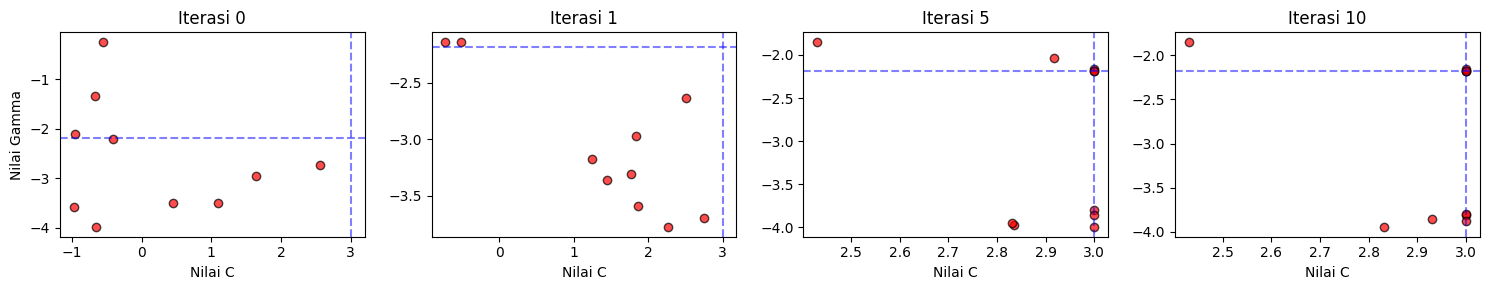

In [ ]:
import matplotlib.pyplot as plt

# Pilih iterasi yang ingin ditinjau
selected_iters = [0, 1, 5, 10]

plt.figure(figsize=(15, 3))
for idx, it in enumerate(selected_iters, 1):
    plt.subplot(1, len(selected_iters), idx)
    p = pop_history[it]

    # Plot posisi 15 paus
    plt.scatter(p[:, 0], p[:, 1], color='red', alpha=0.7, edgecolors='black')
    plt.axvline(
        x=best_log_params[0], color='blue', linestyle='--', alpha=0.5
    )  # Titik C Terbaik
    plt.axhline(
        y=best_log_params[1], color='blue', linestyle='--', alpha=0.5
    )  # Titik Gamma Terbaik

    plt.title(f'Iterasi {it}')
    plt.xlabel('Nilai C')
    if idx == 1:
        plt.ylabel('Nilai Gamma')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Ekstraksi Hyperparameter Terbaik
best_C = 10 ** best_log_params[0]
best_gamma = 10 ** best_log_params[1]

# Fit Model Akhir pada Seluruh Dataset
final_svm = SVC(
    C=best_C, gamma=best_gamma, kernel='rbf', random_state=42, probability=True
)
final_svm.fit(X, y)

# Prediksi pada Data Train
y_pred = final_svm.predict(X)

print('=' * 65)
print(' METRIK EVALUASI MODEL SVM OPTIMAL (WSA) ')
print('=' * 65)
print(f'Hyperparameter Terpilih : C = {best_C:.4f}, Gamma = {best_gamma:.4f}')
print(f'Akurasi Final           : {accuracy_score(y, y_pred):.4f}')
print(f'F1-Score Final          : {f1_score(y, y_pred, average="macro"):.4f}')
print('\nClassification Report:')
print(
    classification_report(
        y, y_pred, target_names=['Not Transported', 'Transported']
    )
)

 METRIK EVALUASI MODEL SVM OPTIMAL (WSA) 
Hyperparameter Terpilih : C = 1000.0000, Gamma = 0.0066
Akurasi Final           : 0.8235
F1-Score Final          : 0.8235

Classification Report:
                 precision    recall  f1-score   support

Not Transported       0.83      0.82      0.82      4315
    Transported       0.82      0.83      0.83      4378

       accuracy                           0.82      8693
      macro avg       0.82      0.82      0.82      8693
   weighted avg       0.82      0.82      0.82      8693



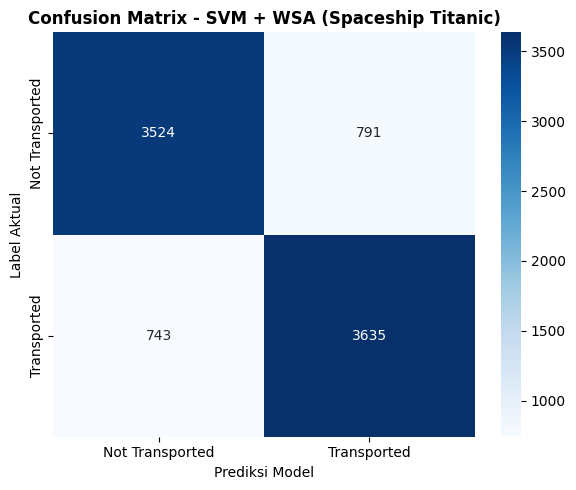

In [ ]:
# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Transported', 'Transported'],
    yticklabels=['Not Transported', 'Transported'],
)
plt.title('Confusion Matrix - SVM + WSA (Spaceship Titanic)', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Aktual')
plt.tight_layout()
plt.show()